# Лабораторна 1. Основні бібліотеки. Лінійні моделі навчання.

В цій лабораторній роботі студенти:
- ознайомлюються з сервісом Colab;
- ознайомлюються з базовими бібліотеками для машинного навчання;
- тренують неглибокі лінійні моделі машинного навчання на базі простих регресій: лінійна, логістична, поліноміальна.

## 0. Налаштування середовища

### 0.0. Імпортуємо залежності

In [106]:
import sys
import os
import random
import numpy as np
import torch
import pandas as pd
import matplotlib.pyplot as plt

### 0.1. Перевіряємо чи ми точно в Colab

In [107]:
IN_COLAB = "google.colab" in sys.modules
print("Running in Colab:", IN_COLAB)

assert IN_COLAB, f"Ця лаба має вокинуватися в Google Colab (https://colab.research.google.com/)"

Running in Colab: True


### 0.2. Фіксуємо всі джерела випадковості.
На GPU повна детермінованість трохи сповільнює тренування
(`cudnn.deterministic = True` вимикає частину швидких алгоритмів) —
тут це не критично, адже дані й модель дрібні.

In [108]:
SEED = 42

def set_seed(seed: int = SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

**Вправа 1.** Скористайся вбудованим модулем `random`. Спробуй `random.randint(1, 100)` і `random.shuffle()` на списку — випадковість буває не лише в числі, а й у перестановці. Згенеруй обома способами двічі ДО виклику `set_seed()` — переконайся, що результати різні. Потім ще двічі ПІСЛЯ, викликаючи `set_seed()`. Після клітинки з кодом створи клітинку з маркдауном і поясни що відбувається після `set_seed()` і як це проявляється в результатах виконання коду.

In [109]:
# TODO: двічі ДО set_seed() -- наприклад random.randint(1, 100) і random.shuffle(numbers)
for i in range(2):
  numbers = list(range(10))

  random.shuffle(numbers)
  random_number = random.randint(1, 100)

  print(random_number, numbers)

76 [2, 5, 7, 8, 6, 1, 4, 0, 9, 3]
98 [1, 6, 8, 9, 7, 3, 5, 2, 0, 4]


In [110]:
# TODO: тепер двічі ПІСЛЯ set_seed() -- виклич set_seed() перед КОЖНИМ
# окремим генеруванням, не один раз на обидва

for i in range(2):
  set_seed()

  numbers = list(range(10))

  random.shuffle(numbers)
  random_number = random.randint(1, 100)

  print(random_number, numbers)

76 [7, 3, 2, 8, 5, 6, 9, 4, 0, 1]
76 [7, 3, 2, 8, 5, 6, 9, 4, 0, 1]


### **Висновок**

Без встановлення seed генератор при кожному виклику продовжує
генерувати псевдовипадкові значення. Тому числа та перестановки
зазвичай відрізняються, хоча іноді можуть випадково збігатися(ймовірність).

Виклик set_seed() повертає генератор до визначеного початкового
стану. Якщо перед кожною спробою встановлювати однаковий seed(42 в нашому випадку) і виконувати однакові дії в однаковому порядку, результати повторюються: отримуємо те саме число й ту саму перестановку списку.

Це корисно для відтворення результатів експериментів.


---


### 0.3. Використовуємо лише CPU (в цій лабі)
На Colab зазвичай є безкоштовний GPU (T4), але для лінійної регресії
на кількасот точок CPU часто не повільніший — виграш GPU з'їдає пересилання
даних на пристрій і назад щоепохи. Тому нижче свідомо тренуємось на CPU.

In [111]:
device_available = torch.device("cuda" if torch.cuda.is_available() else "cpu")
device = torch.device("cpu")

print("Доступний пристрій :", device_available)
print("Використовуємо     :", device)
if device_available.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))

assert device.type == "cpu", f"Ця лаба має виконуватися на CPU, а не на GPU ({device})"

Доступний пристрій : cpu
Використовуємо     : cpu


**Вправа 2.** Встанови CPU рантайм. Запусти комірку вище і зроби скріншот виводу. Потім у Colab зміни рантайм на GPU, перезапусти всі комірки від початку. Знову зроби скріншот тієї самої комірки. Збережи обидва скріншоти — пізніше завантажиш їх на GitHub разом зі здачею лаби.

### 0.4. Монтуємо Google Drive

Сесія Colab обмежена в часі й може скинутись — усе в `/content` зникає разом
з нею. Монтуємо Drive, щоб чекпоінт моделі й логи TensorBoard пережили
перезапуск.

In [112]:
from google.colab import drive
drive.mount("/content/drive")
ARTIFACT_DIR = "/content/drive/MyDrive/ai_systems/lab1"


os.makedirs(ARTIFACT_DIR, exist_ok=True)
RUNS_DIR = os.path.join(ARTIFACT_DIR, "runs")
os.makedirs(RUNS_DIR, exist_ok=True)
print("Артефакти зберігаються в:", ARTIFACT_DIR)


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Артефакти зберігаються в: /content/drive/MyDrive/ai_systems/lab1


---
## 1. Ознайомлення з бібліотеками

Кілька дуже простих вправ на NumPy, pandas, PyTorch і Matplotlib — щоб мати
спільну базу перед тим, як усі чотири підуть у хід одночасно.

### 1.1. NumPy

Документація: https://numpy.org/doc/stable/

**Вправа 3.** Створи масив форми 3×4, заповнений нулями (`np.zeros`), і ще один такої самої форми, заповнений числом 7 (`np.full`). Виведи форму (`.shape`) і тип даних (`.dtype`) обох.

In [113]:
# TODO: zeros_arr = np.zeros((3, 4))
# TODO: sevens_arr = np.full((3, 4), 7)

zeros_arr = np.zeros((3,4))
sevens_arr = np.full((3, 4), 7)

print(zeros_arr, zeros_arr.shape if zeros_arr is not None else None, zeros_arr.dtype if zeros_arr is not None else None)
print("\n")
print(sevens_arr, sevens_arr.shape if sevens_arr is not None else None, sevens_arr.dtype if sevens_arr is not None else None)


[[0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]] (3, 4) float64


[[7 7 7 7]
 [7 7 7 7]
 [7 7 7 7]] (3, 4) int64


**Вправа 4.** Створи масив від 0 до 20 із кроком 2 через `np.arange`, і масив із 5 рівномірно розподілених точок від 0 до 1 через `np.linspace`. Виведи обидва.

In [114]:
# TODO: arange_arr = np.arange(0, 20, 2)
# TODO: linspace_arr = np.linspace(0, 1, 5)
arange_arr = np.arange(0, 20, 2)
linspace_arr = np.linspace(0, 1, 5)

print(arange_arr)
print(linspace_arr)

[ 0  2  4  6  8 10 12 14 16 18]
[0.   0.25 0.5  0.75 1.  ]


**Вправа 5.** Створи одиничну матрицю 4×4 (`np.eye`) і випадковий масив цілих чисел форми 3×3 у діапазоні [0, 10) (`np.random.randint`). Виведи `.ndim` обох масивів.

In [115]:
# TODO: identity = np.eye(4)
# TODO: random_ints = np.random.randint(0, 10, size=(3, 3))
identity = np.eye(4)
random_ints = np.random.randint(0, 10, size=(3, 3))

print(identity.ndim)
print(random_ints.ndim)


2
2


**Вправа 6.** Маєш масив оцінок студентів. Порахуй середнє, стандартне відхилення і z-normalized версію масиву — без циклів.

In [116]:
scores = np.array([78, 85, 92, 67, 90, 74, 88, 95, 60, 82])

# TODO: порахувати mean, std і z_scores = (scores - mean) / std
mean = np.mean(scores)
std = np.std(scores)
z_scores = (scores - mean) / std

print("Середнє:", mean, " Std:", std)
print("Z-scores:", z_scores)


Середнє: 81.1  Std: 10.76522178127325
Z-scores: [-0.28796434  0.36227772  1.01251978 -1.30977329  0.82673633 -0.65953123
  0.64095289  1.29119495 -1.96001536  0.08360255]


**Вправа 7.** Маєш 1D масив із 12 чисел. Перетвори його на матрицю 3×4 і порахуй суму кожного рядка та кожного стовпця.

In [117]:
arr = np.arange(1, 13)

# TODO: перетворити arr на матрицю 3x4 (reshape), порахувати суми по рядках
# (axis=1) і по стовпцях (axis=0)
matrix = arr.reshape(3,4)
row_sums = matrix.sum(axis=1)
col_sums = matrix.sum(axis=0)

print(matrix)
print("Сума по рядках:  ", row_sums)
print("Сума по стовпцях:", col_sums)


[[ 1  2  3  4]
 [ 5  6  7  8]
 [ 9 10 11 12]]
Сума по рядках:   [10 26 42]
Сума по стовпцях: [15 18 21 24]


### 1.2. pandas

Документація: https://pandas.pydata.org/docs/

**Вправа 8.** Створи таблицю студентів з оцінками. Виведи тільки тих, хто набрав більше 80 балів, відсортованих за спаданням оцінки.

In [118]:
df = pd.DataFrame({
    "name": ["Анна", "Богдан", "Ірина", "Олег", "Марія"],
    "score": [78, 92, 85, 60, 81]
})

# TODO: відфільтрувати score > 80 і відсортувати за score за спаданням
top = df.loc[df["score"] >  80].sort_values("score",ascending=False)
print(top)


     name  score
1  Богдан     92
2   Ірина     85
4   Марія     81


**Вправа 9.** Додай колонку `grade`: `A` якщо `score >= 90`, `B` якщо `score >= 75`, інакше `C`.

In [119]:
# TODO: додати колонку "grade"
# умови: score >= 90 -> "A", score >= 75 -> "B", інакше -> "C"
conditions = [
    df["score"] >= 90,
    df["score"] >= 75,
    df["score"] < 75
]

values = ["A", "B", "C"]

df["grade"] = np.select(conditions, values, default="Unknown")
print(df)

     name  score grade
0    Анна     78     B
1  Богдан     92     A
2   Ірина     85     B
3    Олег     60     C
4   Марія     81     B


### 1.3. PyTorch

Документація: https://pytorch.org/docs/stable/index.html

**Вправа 10.** Створи тензор форми 2×3, заповнений нулями (`torch.zeros`), і ще один такої самої форми, заповнений числом 7 (`torch.full`). Виведи форму (`.shape`) і тип даних (`.dtype`) обох.

In [120]:
# TODO: zeros_t = torch.zeros((2, 3))
# TODO: sevens_t = torch.full((2, 3), 7)
zeros_t = torch.zeros((2, 3))
sevens_t = torch.full((2, 3), 7)

print(zeros_t,zeros_t.shape,zeros_t.dtype)
print(sevens_t,sevens_t.shape,sevens_t.dtype)

tensor([[0., 0., 0.],
        [0., 0., 0.]]) torch.Size([2, 3]) torch.float32
tensor([[7, 7, 7],
        [7, 7, 7]]) torch.Size([2, 3]) torch.int64


**Вправа 11.** Створи тензор від 0 до 20 із кроком 2 через `torch.arange`, і тензор із 5 рівномірно розподілених точок від 0 до 1 через `torch.linspace`.

In [121]:
# TODO: arange_t = torch.arange(0, 20, 2)
# TODO: linspace_t = torch.linspace(0, 1, 5)
arange_t = torch.arange(0, 20, 2)
linspace_t = torch.linspace(0, 1, 5)

print(arange_t)
print(linspace_t)

tensor([ 0,  2,  4,  6,  8, 10, 12, 14, 16, 18])
tensor([0.0000, 0.2500, 0.5000, 0.7500, 1.0000])


**Вправа 12.** Створи тензор напряму зі списку — `torch.tensor([[1, 2], [3, 4]])` — і випадковий тензор форми 3×3 через `torch.rand`. Виведи `.shape`, `.dtype` і `.ndim` обох.

In [122]:
# TODO: from_list = torch.tensor([[1, 2], [3, 4]])
# TODO: random_t = torch.rand(3, 3)

from_list = torch.tensor([[1, 2], [3, 4]])
random_t = torch.rand(3, 3)

print(from_list)
print("Shape:", from_list.shape)
print("Dtype:", from_list.dtype)
print("Ndim:", from_list.ndim)
print('\n')
print(random_t)
print("Shape:", random_t.shape)
print("Dtype:", random_t.dtype)
print("Ndim:", random_t.ndim)

tensor([[1, 2],
        [3, 4]])
Shape: torch.Size([2, 2])
Dtype: torch.int64
Ndim: 2


tensor([[0.8823, 0.9150, 0.3829],
        [0.9593, 0.3904, 0.6009],
        [0.2566, 0.7936, 0.9408]])
Shape: torch.Size([3, 3])
Dtype: torch.float32
Ndim: 2


**Вправа 13.** Створи тензор `x = 5.0` з `requires_grad=True`, порахуй `y = x**2` і перевір автоматичний градієнт проти аналітичного ($dy/dx = 2x$).

In [123]:
n = 5.0

# TODO: x = torch.tensor(n, requires_grad=True), y = x ** 2, y.backward()

x = torch.tensor(n, requires_grad=True)
y = x ** 2
y.backward()

# надрукувати x.grad.item() і порівняти з 2 * n
print(x.grad.item())

analytical = 2 * n
print('Чи автоматичний градієнт = аналітичному:',x.grad.item() == analytical)


10.0
Чи автоматичний градієнт = аналітичному: True


**Вправа 14.** Знайди $x$, який мінімізує $(x-3)^2 + 5$ — не аналітично, а градієнтним спуском: `x` як параметр з `requires_grad=True`, без жодної моделі.

In [124]:
x = torch.tensor(0.0, requires_grad=True)
lr = 0.1

# TODO: цикл градієнтного спуску (20 кроків):
for _ in range(20):
  loss = (x - 3) ** 2 + 5
  loss.backward()
  with torch.no_grad():
      x -= lr * x.grad
  x.grad.zero_()

print(f"x = {x.item():.4f}  (мінімум у x=3)")


x = 2.9654  (мінімум у x=3)


### 1.4. Matplotlib

Документація: https://matplotlib.org/stable/index.html

**Вправа 15.** Побудуй графік функції $y = \sin(x)$ на проміжку $[0, 2\pi]$.

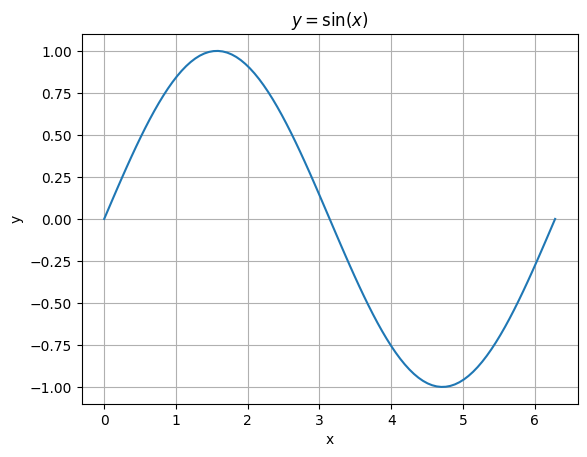

In [125]:
# TODO: xs = np.linspace(0, 2*np.pi, 100), plt.plot(xs, np.sin(xs)), plt.show()
xs = np.linspace(0, 2 * np.pi, 100)
plt.plot(xs, np.sin(xs))

plt.title(r"$y = \sin(x)$")
plt.xlabel("x")
plt.ylabel("y")
plt.grid(True)

plt.show()

**Вправа 16.** На одному графіку познач дві групи точок різними кольорами і додай легенду.

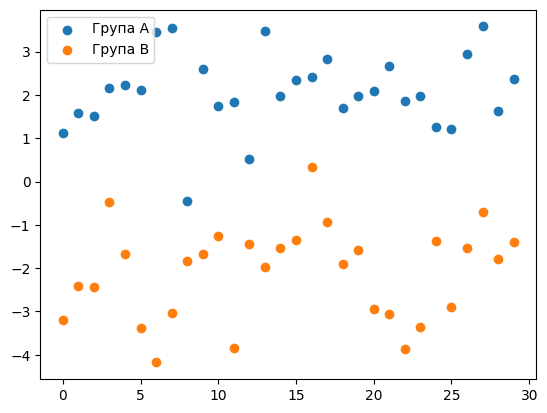

In [126]:
group_a = np.random.randn(30) + 2
group_b = np.random.randn(30) - 2

# TODO: scatter обох груп різними кольорами (color="C0"/"C1", label=...),
x = np.arange(len(group_a))

plt.scatter(x, group_a, color="C0", label="Група A")
plt.scatter(x, group_b, color="C1", label="Група B")

# додати plt.legend(), plt.show()
plt.legend()
plt.show()


---
## Завдання 1. Лінійна регресія

Тренуємо базовий пайплайн на простій лінійній регресії з одним параметром.

$$y = w \cdot x + b + \varepsilon, \quad \varepsilon \sim \mathcal{N}(0, 1)$$

In [127]:
TASK1_TRUE_W = 2.0
TASK1_TRUE_B = 1.0
TASK1_N = 300

x1 = torch.empty(TASK1_N, 1).uniform_(-5, 5)
noise = 1.0 * torch.randn(TASK1_N, 1)
y1 = TASK1_TRUE_W * x1 + TASK1_TRUE_B + noise

**Вправа 17.** Перш ніж будувати модель — подивись на самі дані.

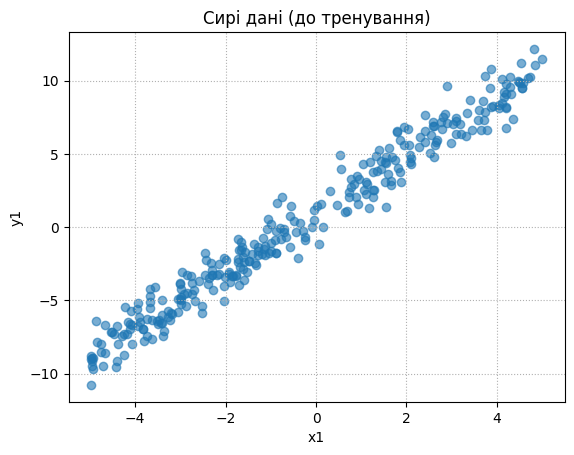

In [128]:
# TODO: Точкова діаграма (scatter plot) з вісями x1 та y1, підпис осей (xlabel/ylabel), заголовок
plt.scatter(x1, y1, alpha=0.6)

plt.xlabel("x1")
plt.ylabel("y1")

plt.title("Сирі дані (до тренування)")
plt.grid(True, linestyle=":")
plt.show()

**Вправа 18.** Розбий дані на train/val/test (70/15/15). Перемішай дані перед зрізом, інакше спліт вийде не випадковим.

In [129]:
# TODO: перемішати x1/y1 через torch.randperm(TASK1_N), розбити на
# train/val/test у пропорції 70/15/15
# x_train1, y_train1 = ...
# x_val1, y_val1 = ...
# x_test1, y_test1 = ...

indices = torch.randperm(TASK1_N)
n_train = int(0.70 * TASK1_N)
n_val = int(0.15 * TASK1_N)

x_train1, y_train1 = x1[indices[:n_train]], y1[indices[:n_train]]
x_val1, y_val1 = x1[indices[n_train:n_train + n_val]], y1[indices[n_train:n_train + n_val]]
x_test1, y_test1 = x1[indices[n_train + n_val:]], y1[indices[n_train + n_val:]]

print(f"train/val/test: {len(x_train1)}/{len(x_val1)}/{len(x_test1)}")


train/val/test: 210/45/45


**Вправа 19.** Нижче — готовий цикл навчання, кожен крок підписаний окремо. Просто запусти обидві комірки й подивись, як модель наближається до `true` за 100 епох (знімки кожні 30 епох).

In [130]:
task1_model = torch.nn.Linear(in_features=1, out_features=1)
optimizer = torch.optim.SGD(task1_model.parameters(), lr=0.05)
loss_fn = torch.nn.MSELoss()

x_line = torch.linspace(-5, 5, 100).unsqueeze(1)  # сітка для візуалізації лінії
snapshots = []  # (epoch, w, b, y_line_pred) кожні 30 епох

for epoch in range(100):
    # обнулити градієнти з попереднього кроку
    optimizer.zero_grad()
    # forward -- прогноз моделі на поточних w, b
    y_pred = task1_model(x_train1)
    # loss -- наскільки прогноз відрізняється від y_train1
    loss = loss_fn(y_pred, y_train1)
    # backward -- градієнти loss за w і b
    loss.backward()
    # крок оптимізатора -- оновити w і b
    optimizer.step()

    if epoch % 30 == 0 or epoch == 99:
        with torch.no_grad():
            y_line_pred = task1_model(x_line)
        snapshots.append((epoch, task1_model.weight.item(), task1_model.bias.item(), y_line_pred))
        print(f"epoch {epoch:4d}  loss={loss.item():.6f}  "
              f"w={task1_model.weight.item():.4f} (true {TASK1_TRUE_W})  "
              f"b={task1_model.bias.item():.4f} (true {TASK1_TRUE_B})")


epoch    0  loss=10.796704  w=1.7971 (true 2.0)  b=-0.2009 (true 1.0)
epoch   30  loss=1.030498  w=1.9806 (true 2.0)  b=1.0221 (true 1.0)
epoch   60  loss=1.026565  w=1.9829 (true 2.0)  b=1.0764 (true 1.0)
epoch   90  loss=1.026557  w=1.9830 (true 2.0)  b=1.0788 (true 1.0)
epoch   99  loss=1.026557  w=1.9830 (true 2.0)  b=1.0789 (true 1.0)


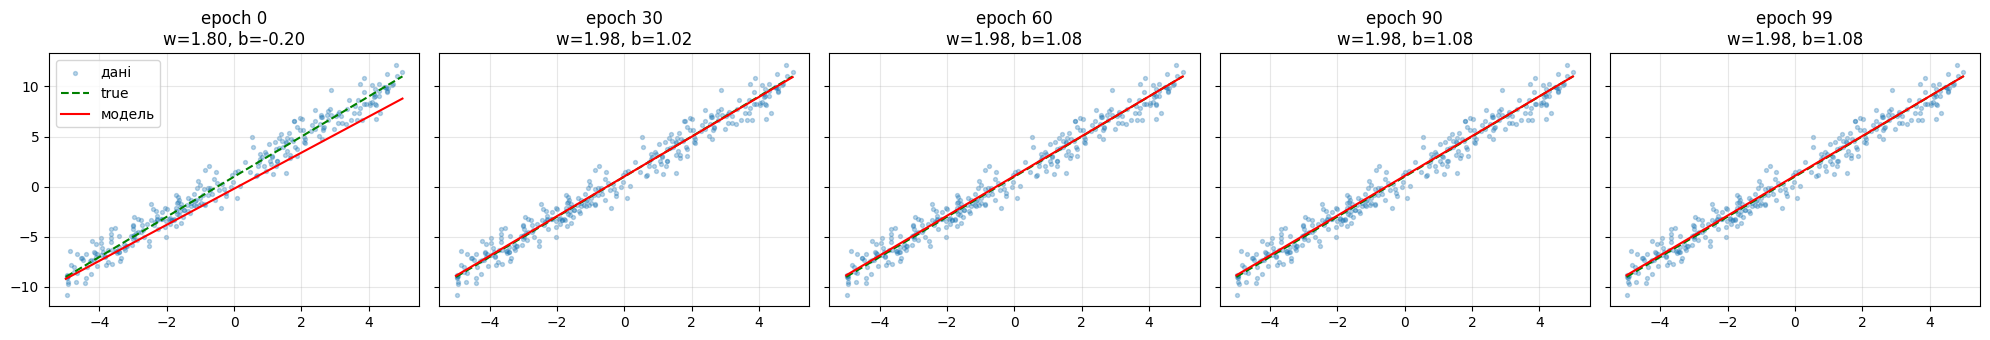

In [131]:
with torch.no_grad():
    y_line_true = TASK1_TRUE_W * x_line + TASK1_TRUE_B

fig, axes = plt.subplots(1, len(snapshots), figsize=(4 * len(snapshots), 3.5), sharey=True)
for ax, (epoch, w, b, y_line_pred) in zip(axes, snapshots):
    ax.scatter(x1.numpy(), y1.numpy(), s=8, alpha=0.3, label="дані")
    ax.plot(x_line.numpy(), y_line_true.numpy(), "g--", label="true")
    ax.plot(x_line.numpy(), y_line_pred.numpy(), "r-", label="модель")
    ax.set_title(f"epoch {epoch}\nw={w:.2f}, b={b:.2f}")
    ax.grid(alpha=0.3)
axes[0].legend()
plt.tight_layout()
plt.show()


**Вправа 20.** Придумай власний напів-реальний сценарій лінійної залежності
(наприклад: кількість з'їдених пачок чіпсів на тиждень → індекс маси тіла;
години сну → продуктивність; щось своє). У markdown-комірці перед кодом
опиши сценарій: яку залежність ти
закладаєш ($w$, $b$) і чому саме такі значення видались тобі правдоподібними.
Згенеруй дані з шумом, збережи їх у CSV файл (за зразком відповідної частини лекції)
і натренуй лінійну регресію за тим самим патерном — спліт, цикл навчання, перевірка на test.
Організуй код тренування у логічні перевикористовувані функції.

### Сценарій: Вплив вживання енергетика Revo на життєздатність серця

Досліджуємо залежність між кількістю випитих бляшанок Revo на тиждень ($x \in [0, 10]$) та умовним індексом здоров'я серця за 100-бальною шкалою ($y$).

* **$b = 100.0$:** Базовий стан здорової серцево-судинної системи за відсутності вживання енергетиків ($x = 0$).
* **$w = -7.0$:** Кожна регулярна бляшанка знижує тонус серця в середньому на 7 пунктів через вплив ударної дози кофеїну, таурину та алкоголю.
* **$\varepsilon \sim \mathcal{N}(0, 3.0^2)$:** Індивідуальна генетична витривалість організму та фоновий розкид.

In [132]:
TRUE_W = -7.0
TRUE_B = 100.0
N = 300
NOISE_STD = 3.0

revo_cans = np.random.uniform(0, 10, size=N)
noise = np.random.normal(0, NOISE_STD, size=N)
heart_health = TRUE_W * revo_cans + TRUE_B + noise

df = pd.DataFrame({"revo_cans": revo_cans, "heart_health": heart_health})

if "ARTIFACT_DIR" in globals():
  df.to_csv(os.path.join(ARTIFACT_DIR, "dataset.csv"), index=False)
df.to_csv("dataset.csv", index=False)


def prepare_data(df):
  x_raw = torch.tensor(df["revo_cans"].values, dtype=torch.float32).unsqueeze(1)
  y = torch.tensor(df["heart_health"].values, dtype=torch.float32).unsqueeze(1)

  x_mean, x_std = x_raw.mean(), x_raw.std()
  x = (x_raw - x_mean) / x_std

  perm = torch.randperm(len(df))
  n_train = int(0.70 * len(df))
  n_val = int(0.15 * len(df))

  train_idx = perm[:n_train]
  val_idx = perm[n_train : n_train + n_val]
  test_idx = perm[n_train + n_val :]

  return (
      x[train_idx],
      y[train_idx],
      x[val_idx],
      y[val_idx],
      x[test_idx],
      y[test_idx],
      x_mean,
      x_std,
  )


def train_model(x_train, y_train, epochs=100, lr=0.05):
  model = torch.nn.Linear(in_features=1, out_features=1)
  optimizer = torch.optim.SGD(model.parameters(), lr=lr)
  loss_fn = torch.nn.MSELoss()

  for _ in range(epochs):
    optimizer.zero_grad()
    loss = loss_fn(model(x_train), y_train)
    loss.backward()
    optimizer.step()
  return model

def evaluate_model(model, x_test, y_test):
  loss_fn = torch.nn.MSELoss()
  with torch.no_grad():
    test_loss = loss_fn(model(x_test), y_test).item()
  return test_loss


x_tr, y_tr, x_val, y_val, x_te, y_te, x_mean, x_std = prepare_data(df)
model = train_model(x_tr, y_tr, epochs=100, lr=0.05)
test_loss = evaluate_model(model, x_te, y_te)

w_eff = model.weight.item() / x_std.item()
b_eff = model.bias.item() - (model.weight.item() * x_mean.item() / x_std.item())

print(f"Оцінені параметри: w = {w_eff:.2f} (true {TRUE_W}), b = {b_eff:.2f} (true {TRUE_B})")
print(f"Помилка на тестовій вибірці (Test MSE): {test_loss:.2f}")

Оцінені параметри: w = -6.81 (true -7.0), b = 99.08 (true 100.0)
Помилка на тестовій вибірці (Test MSE): 11.76


**Вправа 21.** Збережи натреновану модель на своєму гугл диску у файлі з назвою `model.pt`.
Збережений файл потрібно буде також здати разом з лабою.

In [133]:
import os
import torch

model_path = os.path.join(ARTIFACT_DIR, "model.pt")

checkpoint = {
    "state_dict": model.state_dict(),
    "x_mean": x_mean.item(),
    "x_std": x_std.item(),
}

torch.save(checkpoint, model_path)

torch.save(checkpoint, "model.pt")

print("Модель успішно збережено на Google Диску:", model_path)
print("Локальну копію збережено:", os.path.exists("model.pt"))

Модель успішно збережено на Google Диску: /content/drive/MyDrive/ai_systems/lab1/model.pt
Локальну копію збережено: True


**Вправа 22.** Встанови [Gradio](https://gradio.app/)
```
!pip install -q gradio
import gradio as gr
```
Завантаж свою модель, збережену в попередній вправі і створи інтерактивну аппку.

In [134]:
!pip install -q gradio
import gradio as gr

In [135]:
import os
import torch

model_path = (
    os.path.join(ARTIFACT_DIR, "model.pt")
    if "ARTIFACT_DIR" in globals()
    else "model.pt"
)
checkpoint = torch.load(model_path, weights_only=False)

loaded_model = torch.nn.Linear(in_features=1, out_features=1)
loaded_model.load_state_dict(checkpoint["state_dict"])
loaded_model.eval()

loaded_x_mean = checkpoint["x_mean"]
loaded_x_std = checkpoint["x_std"]


def predict_heart_health(revo_cans: float) -> float:
  x_input = torch.tensor([[revo_cans]], dtype=torch.float32)
  x_input_norm = (x_input - loaded_x_mean) / loaded_x_std
  with torch.no_grad():
    health_pred = loaded_model(x_input_norm).item()

  health_pred = max(0.0, min(100.0, health_pred))
  return round(health_pred, 1)


demo = gr.Interface(
    fn=predict_heart_health,
    inputs=gr.Slider(
        0, 10, value=2, step=1, label="Кількість бляшанок Revo на тиждень"
    ),
    outputs=gr.Number(label="Прогноз здоров'я серця (0 - 100)"),
    title="Revo -> Життєздатність серця",
    description=(
        "Лінійна регресія з Вправи 20. Пересувайте повзунок, щоб побачити"
        " прогноз стану серця залежно від спожитої кількості енергетиків."
    ),
)

demo.launch()

It looks like you are running Gradio on a hosted Jupyter notebook, which requires `share=True`. Automatically setting `share=True` (you can turn this off by setting `share=False` in `launch()` explicitly).

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://8ef48b6fed4369e742.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


---
### Як здавати лабу
У [форму](https://forms.gle/5qxRYshxKknBXDCz8) здати посилання на **публічний** репозиторій, який містить:
1. **Цей ноутбук з усіма виконаними вправами**. Ноутбук має запускатися зверху до низу (Run All) в будь-якому середовищі без помилок.
2. **Додаткові скріншоти** по ходу виконання лаби (якими Ви доводите, що справді виконували цбю лабу).
3. Створений по ходу виконання лаби **csv файл** з даними і **pt файл** з моделлю.
4. Структура файлів на репозиторії, **точно дотримуйтесь, інакше не зарахується лаба**:
```
    /lab1/linear_models_lab.ipynb
    /lab1/screenshots/*
    /lab1/dataset.csv
    /lab1/model.pt
```